In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import seaborn as sns
import numpy as np

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving archive (2).zip to archive (2).zip


In [ ]:
df = pd.read_csv('archive (2).zip', header=None,
    names=[
        "user_id",
        "game_title",
        "behavior_name",
        "value",
        "extra_column"
    ]
)
df.head(10)

,user_id,game_title,behavior_name,value,extra_column
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
1,151603712,The Elder Scrolls V Skyrim,play,273.0,0
2,151603712,Fallout 4,purchase,1.0,0
3,151603712,Fallout 4,play,87.0,0
4,151603712,Spore,purchase,1.0,0
5,151603712,Spore,play,14.9,0
6,151603712,Fallout New Vegas,purchase,1.0,0
7,151603712,Fallout New Vegas,play,12.1,0
8,151603712,Left 4 Dead 2,purchase,1.0,0
9,151603712,Left 4 Dead 2,play,8.9,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 5 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   user_id        200000 non-null  int64  
 1   game_title     200000 non-null  object 
 2   behavior_name  200000 non-null  object 
 3   value          200000 non-null  float64
 4   extra_column   200000 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 7.6+ MB


In [ ]:
df.isna().sum()

,0
user_id,0
game_title,0
behavior_name,0
value,0
extra_column,0


In [ ]:
filas, columnas = df.shape

print(f"registros: {filas:,}")
print(f"columnas: {columnas}")
print(f"unicos: {df['user_id'].nunique():,}")
print(f"videojuegos únicos: {df['game_title'].nunique():,}")

registros: 200,000
columnas: 5
unicos: 12,393
videojuegos únicos: 5,155


In [ ]:
print("\nValores nulos por columna:")
print(df.isnull().sum())


Valores nulos por columna:
user_id          0
game_title       0
behavior_name    0
value            0
extra_column     0
dtype: int64


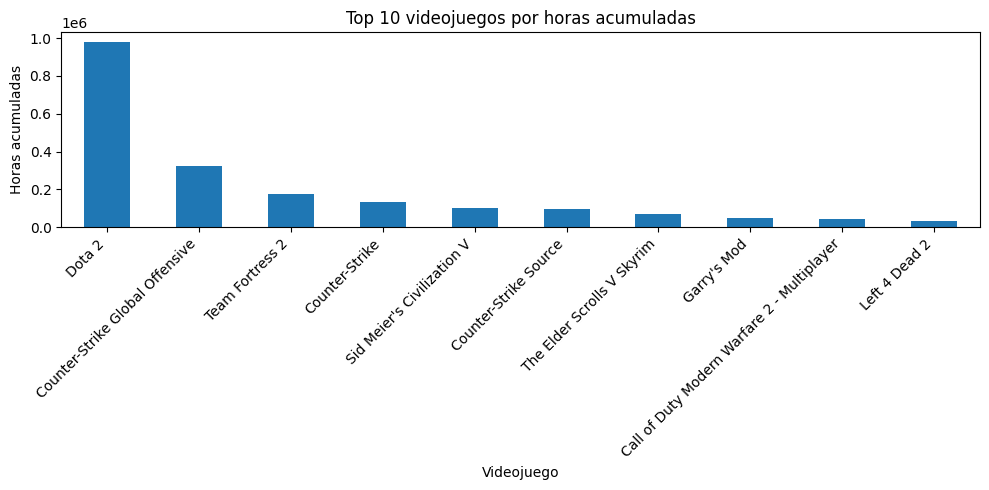

In [ ]:
juegos = df[df["behavior_name"] == "play"].copy()

top_horas = (
    juegos.groupby("game_title")["value"]
    .sum()
    .nlargest(10)
    # orden descendente: el juego con más horas queda a la izquierda
)

top_horas.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 10 videojuegos por horas acumuladas")
plt.xlabel("Videojuego")
plt.ylabel("Horas acumuladas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

PREPARACION DE DATOS

In [ ]:
df_puro= df[
    ["user_id", "game_title", "behavior_name", "value"]
].copy()

In [ ]:
df_puro["value"] = pd.to_numeric(
    df_puro["value"], errors="coerce"
)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 5 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   user_id        200000 non-null  int64  
 1   game_title     200000 non-null  object 
 2   behavior_name  200000 non-null  object 
 3   value          200000 non-null  float64
 4   extra_column   200000 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 7.6+ MB


In [ ]:

df_puro = df_puro.drop_duplicates()

print("Registros Limpios", len(df_puro))

Registros Limpios 199293


Se realiza la limpieza y transformación de los datos y se eliminan los duplicados para tener una mejor visión de la información mediante las gráficas.

In [ ]:
compras = df_puro[
    df_puro["behavior_name"] == "purchase"
]

partidas = df_puro[
   df_puro["behavior_name"] == "play"
]


In [ ]:
horas_juego = (
    partidas.groupby(["user_id", "game_title"])["value"]
    .sum()
    .reset_index()
)

In [ ]:
usuarios = pd.concat(
    [compras_usuario, actividad_usuario],
    axis=1
).fillna(0)

print("Dimensiones de la tabla de usuarios:", usuarios.shape)
display(usuarios.head())

Dimensiones de la tabla de usuarios: (12393, 4)


,games_purchased,games_played,total_hours,avg_hours_per_game
user_id,,,,
5250,21,6.0,225.5,37.583333
76767,36,20.0,1227.0,61.350000
86540,82,15.0,255.0,17.000000
103360,10,0.0,0.0,0.000000
144736,8,1.0,0.1,0.100000


In [ ]:
# Caracteristicas de actividad

actividad_usuario = (
    horas_juego.groupby("user_id")
    .agg(
        games_played=("game_title", "nunique"),
        total_hours=("value", "sum"),
        avg_hours_per_game=("value", "mean")
    )
)

In [ ]:
# Escalar las variables para el clustering
variables = [
    "games_purchased",
    "games_played",
    "total_hours",
    "avg_hours_per_game",
]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(usuarios[variables])

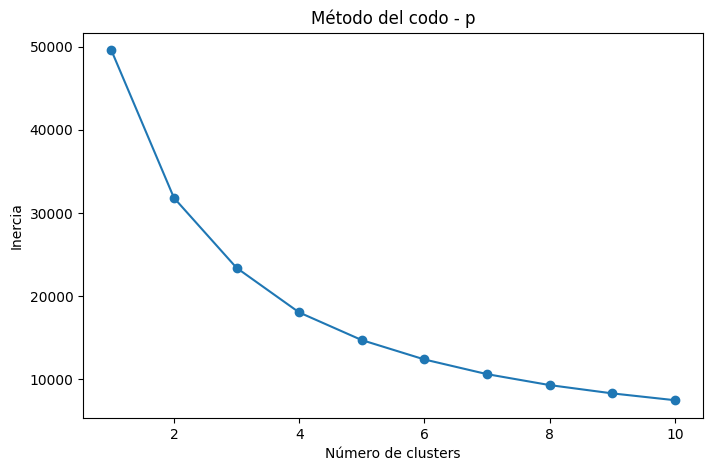

In [ ]:
inercia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inercia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inercia, marker='o')
plt.title('Método del codo - p')
plt.xlabel('Número de clusters')
plt.ylabel('Inercia')
plt.show()


In [ ]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

usuarios['cluster'] = kmeans.fit_predict(X_scaled)

print("Cantidad de usuarios por cluster:")
print(usuarios['cluster'].value_counts().sort_index())

Cantidad de usuarios por cluster:
cluster
0    11342
1      513
2       56
3      471
4       11
Name: count, dtype: int64


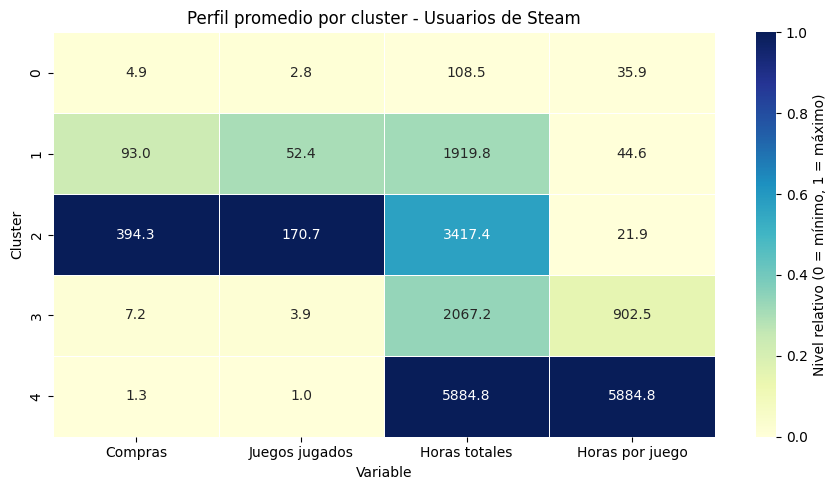

In [ ]:
variables = ["games_purchased", "games_played", "total_hours", "avg_hours_per_game"]

perfil = usuarios.groupby("cluster")[variables].mean()

# Normalizar por columna (0 a 1) para comparar variables con escalas distintas
perfil_norm = (perfil - perfil.min()) / (perfil.max() - perfil.min())

plt.figure(figsize=(9, 5))
sns.heatmap(
    perfil_norm,
    annot=perfil.round(1),   # muestra los promedios reales
    fmt="",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Nivel relativo (0 = mínimo, 1 = máximo)"},
)
plt.title("Perfil promedio por cluster - Usuarios de Steam")
plt.xlabel("Variable")
plt.ylabel("Cluster")
plt.xticks(
    ticks=[0.5, 1.5, 2.5, 3.5],
    labels=["Compras", "Juegos jugados", "Horas totales", "Horas por juego"],
    rotation=0,
)
plt.tight_layout()
plt.show()

El mapa de calor muestra el perfil promedio de cada cluster. Entre más oscuro el color, mayor es el valor de ese grupo frente a los demás. El cluster 0 tiene valores bajos en todo, así que son jugadores casuales. El cluster 1 tiene una biblioteca amplia y bastantes horas de juego, por lo que son usuarios activos. El cluster 2 es el que más compra y más juegos tiene, pero juega poco cada uno, lo que lo hace parecer coleccionistas. El cluster 3 tiene pocos juegos, pero les dedica muchísimas horas, así que son jugadores especializados. Por último, el cluster 4 acumula las horas más altas en prácticamente un solo juego, es decir, usuarios hardcore de un único título.

## 4. Interpretación de los clusters

El mapa de calor muestra el perfil promedio de cada grupo. Entre más oscuro el color, mayor es el valor de ese grupo frente a los demás.

- **Cluster 0 – Jugadores casuales:** tienen pocas compras (4.9), pocos juegos jugados (2.8) y pocas horas totales (108.5). Entran a la plataforma de forma ocasional y su compromiso es bajo.
- **Cluster 1 – Jugadores activos y diversos:** cuentan con una biblioteca amplia (93 compras y 52.4 juegos jugados) y dedican bastante tiempo (1,919.8 horas). Juegan varios títulos de manera constante.
- **Cluster 2 – Coleccionistas:** son el grupo que más compra (394.3) y más juegos juega (170.7), pero dedican pocas horas a cada uno (21.9). Compran y prueban muchos títulos sin profundizar en ninguno.
- **Cluster 3 – Jugadores especializados:** tienen pocos juegos (3.9), pero les dedican muchísimas horas (902.5 por juego). Se concentran en un número reducido de títulos.
- **Cluster 4 – Usuarios hardcore de un solo juego:** acumulan las horas más altas (5,884.8) en prácticamente un único título (1.0 juego y 1.3 compras). Casi no compran, pero su dedicación es extrema.

## 5. Recomendaciones de negocio

### ¿Qué estrategia de marketing implementaría para cada grupo?

- **Cluster 0 (casuales):** campañas de activación con recomendaciones de juegos populares, versiones de prueba gratuitas y descuentos de bienvenida para incentivar que jueguen más.
- **Cluster 1 (activos y diversos):** recomendaciones personalizadas según los géneros que ya juegan y avisos de lanzamientos relacionados con su biblioteca.
- **Cluster 2 (coleccionistas):** son los que más ingresos generan por compras, así que recibirían paquetes, ofertas por temporada y notificaciones de rebajas. También se les recomendarían juegos de su biblioteca que aún no han jugado, para que los aprovechen.
- **Cluster 3 (especializados):** contenido relacionado con sus juegos favoritos, como expansiones, DLC, ediciones especiales y novedades de los desarrolladores.
- **Cluster 4 (hardcore):** programas de reconocimiento, acceso anticipado a contenido y recomendaciones de títulos similares para que amplíen su biblioteca.



### ¿Qué usuarios priorizaría para campañas de fidelización?

Priorizaría los clusters 1 y 3. El cluster 1 combina compras y horas altas, por lo que es el más valioso y estable. El cluster 3 ya tiene una gran dedicación, y